In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from ase.db import connect
from tqdm import tqdm

In [2]:
data_dir = os.path.expanduser("~/Desktop/train_4M")
shards = sorted([
    os.path.join(data_dir, f) 
    for f in os.listdir(data_dir) 
    if f.endswith(".aselmdb")
])

db = connect(shards[0])

print("Entries in shard:", len(db))

Entries in shard: 49835


In [3]:
N_list = []
pair_weight_list = []
Zmax_list = []
Zsum_list = []

for row in tqdm(db.select(), total=len(db)):
    atoms = row.toatoms()
    Z = atoms.get_atomic_numbers()
    
    N = len(Z)
    N_list.append(N)
    
    Z = np.array(Z)
    
    if N > 1:
        top2 = np.partition(Z, -2)[-2:]
        max_pair_weight = int(top2[0] * top2[1])
        Z_max = int(top2.max())
    else:
        max_pair_weight = 0
        Z_max = int(Z[0])
    
    Z_sum = int(Z.sum())
    
    pair_weight_list.append(max_pair_weight)
    Zmax_list.append(Z_max)
    Zsum_list.append(Z_sum)

100%|██████████| 49835/49835 [00:35<00:00, 1405.59it/s]


In [4]:
features = np.column_stack([
    N_list,
    pair_weight_list,
    Zmax_list,
    Zsum_list
])

print("Feature shape:", features.shape)

Feature shape: (49835, 4)


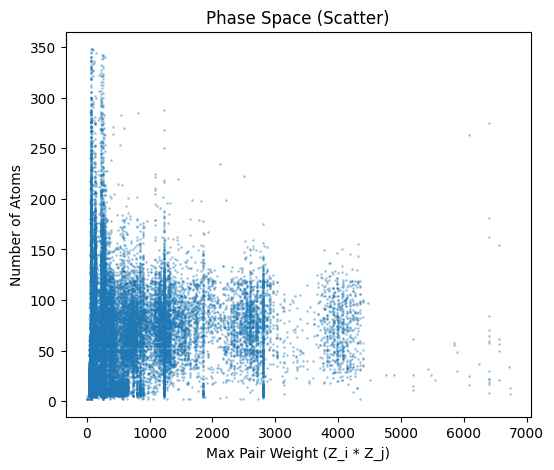

In [5]:
plt.figure(figsize=(6, 5))
plt.scatter(
    features[:, 1],  # max_pair_weight
    features[:, 0],  # N_atoms
    s=1,
    alpha=0.3
)

plt.xlabel("Max Pair Weight (Z_i * Z_j)")
plt.ylabel("Number of Atoms")
plt.title("Phase Space (Scatter)")
plt.show()

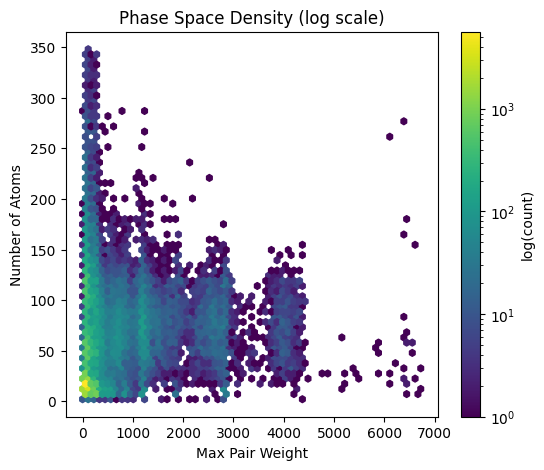

In [11]:
plt.figure(figsize=(6, 5))
plt.hexbin(
    features[:, 1],
    features[:, 0],
    gridsize=60,
    bins='log'
)

plt.xlabel("Max Pair Weight")
plt.ylabel("Number of Atoms")
plt.title("Phase Space Density (log scale)")
plt.colorbar(label="log(count)")
plt.savefig("phase_space_density_one_shard.png")
plt.show()

In [7]:
np.save("phase_space_shard0.npy", features)